# Online Retail Analytics: From Transactions to Customer Decisions

**Dataset:** [Online Retail II (UCI)](https://archive.ics.uci.edu/dataset/502/online+retail+ii): about 1.07M transaction lines from a UK online gift shop (Dec 2009 to Dec 2011), mostly sold to wholesalers.

**Project summary.** This notebook follows one business question end to end: *who are our customers, what do they buy together, who is about to leave, and how much will they spend next?* It covers the full set of course methods in one story:

| Business question | Method(s) |
|---|---|
| Which products are bought together? | Association rules (FP-Growth) |
| What kinds of customers do we have? | K-Means, Agglomerative (Ward), PCA |
| Who will stop buying in the next 90 days? | Naive Bayes, Decision Tree, Logistic Regression, Random Forest, Gradient Boosting, Stacking ensemble |
| How much will each customer spend in the next 90 days? | Linear Regression vs. ensemble regressor |

Compared to a single-table classification exercise, the main challenges here are **building the modelling table from raw transactions**, **time-based validation without leakage**, and **turning model output into business actions**.

## Table of contents
1. [Setup](#1.-Setup)
2. [Data loading and data-quality audit](#2.-Data-loading-and-data-quality-audit)
3. [Exploratory data analysis](#3.-Exploratory-data-analysis)
4. [Market basket analysis (association rules)](#4.-Market-basket-analysis-(association-rules))
5. [Customer segmentation (clustering + PCA)](#5.-Customer-segmentation-(clustering-+-PCA))
6. [Churn prediction (classification)](#6.-Churn-prediction-(classification))
7. [Customer value prediction (regression)](#7.-Customer-value-prediction-(regression))
8. [Conclusions](#8.-Conclusions)

# 1. Setup

**Question:** what tools do we use, and how do we keep every figure and result reproducible?

All randomness uses one seed, and all figures share one style and one color palette.

In [1]:
# Core
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.stats import spearmanr

# Association rules
from mlxtend.frequent_patterns import association_rules, fpgrowth

# scikit-learn
from sklearn.base import clone
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import (HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              RandomForestClassifier, StackingClassifier)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay,
                             adjusted_rand_score, average_precision_score, confusion_matrix,
                             davies_bouldin_score, f1_score, mean_absolute_error,
                             precision_recall_curve, precision_score, r2_score, recall_score,
                             roc_auc_score, roc_curve, root_mean_squared_error, silhouette_score)
from sklearn.model_selection import (KFold, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_validate)
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)

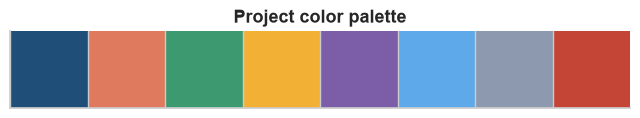

In [2]:
# Reproducibility
SEED = 42
rng = np.random.default_rng(SEED)

# One palette and one style for every figure in the notebook
PALETTE = ["#1F4E79", "#E07A5F", "#3D9970", "#F2B134", "#7B5EA7", "#5DA9E9", "#8D99AE", "#C44536"]
MAIN, ACCENT, GOOD = PALETTE[0], PALETTE[1], PALETTE[2]
SEQ_CMAP = "crest"          # sequential colormap (heatmaps, lift)
DIV_CMAP = "vlag"           # diverging colormap (loadings, correlations)

sns.set_theme(style="whitegrid", context="notebook", palette=PALETTE)
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 100,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})


def style(ax, title, xlabel=None, ylabel=None):
    # Apply consistent title/labels to an axis
    ax.set_title(title)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    return ax


gbp = mtick.FuncFormatter(lambda x, _: f"£{x / 1e6:.1f}M" if abs(x) >= 1e6 else f"£{x / 1e3:.0f}k")
sns.palplot(PALETTE)
plt.title("Project color palette")
plt.show()

**Takeaway:** one seed (`SEED = 42`), one palette, one helper for titles and labels. Every result below can be reproduced exactly.

# 2. Data loading and data-quality audit

**Question:** how much of the raw data can we trust, and which rows have to go before we analyse customers?

The Excel file has two sheets (`Year 2009-2010`, `Year 2010-2011`). Reading the xlsx takes about half a minute, so the concatenated table is cached as a parquet file next to it. The cache is gitignored.

In [3]:
DATA_PATH = Path("online_retail_II.xlsx")
CACHE_PATH = Path("online_retail_II.parquet")

t0 = time.time()
if CACHE_PATH.exists():
    raw = pd.read_parquet(CACHE_PATH)
    source = "parquet cache"
else:
    # Read both sheets and stack them; keep codes as strings so leading zeros/letters survive
    sheets = pd.read_excel(DATA_PATH, sheet_name=None,
                           dtype={"Invoice": str, "StockCode": str, "Description": str})
    raw = pd.concat(sheets.values(), ignore_index=True)
    raw.to_parquet(CACHE_PATH, index=False)
    source = "xlsx (both sheets)"

# Consistent snake_case column names
raw = raw.rename(columns={"Invoice": "invoice", "StockCode": "stock_code", "Description": "description",
                          "Quantity": "quantity", "InvoiceDate": "invoice_date", "Price": "price",
                          "Customer ID": "customer_id", "Country": "country"})
print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns from {source} in {time.time() - t0:.1f}s")
print(f"Period: {raw.invoice_date.min():%Y-%m-%d} to {raw.invoice_date.max():%Y-%m-%d}")
raw.head()

Loaded 1,067,371 rows x 8 columns from xlsx (both sheets) in 34.1s
Period: 2009-12-01 to 2011-12-09


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,"13,085.000",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.000",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.000",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,"13,085.000",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,"13,085.000",United Kingdom


In [4]:
# Column types, missing values and number of unique values
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": raw.isna().mean() * 100,
    "unique": raw.nunique(),
})
audit

,dtype,missing,missing_%,unique
invoice,str,0,0.000,53628
stock_code,str,0,0.000,5305
description,str,4382,0.411,5698
quantity,int64,0,0.000,1057
invoice_date,datetime64[us],0,0.000,47635
price,float64,0,0.000,2807
customer_id,float64,243007,22.767,5942
country,str,0,0.000,43


In [5]:
# Quick look at the main data-quality problems before cleaning
is_cancel = raw.invoice.str.startswith("C")
is_product = raw.stock_code.str.match(r"^\d{5}")   # real products start with 5 digits

quality = pd.Series({
    "Missing customer_id": raw.customer_id.isna().sum(),
    "Cancellation invoices (start with 'C')": is_cancel.sum(),
    "Negative quantity": (raw.quantity < 0).sum(),
    "Negative quantity but NOT a cancellation": ((raw.quantity < 0) & ~is_cancel).sum(),
    "Zero or negative price": (raw.price <= 0).sum(),
    "Non-product stock codes": (~is_product).sum(),
    "Exact duplicate rows": raw.duplicated().sum(),
}, name="rows")
quality.to_frame()

,rows
Missing customer_id,243007
Cancellation invoices (start with 'C'),19494
Negative quantity,22950
Negative quantity but NOT a cancellation,3457
Zero or negative price,6207
Non-product stock codes,6093
Exact duplicate rows,34335


In [6]:
# Which non-product codes exist? (postage, bank charges, manual adjustments, ...)
(raw.loc[~is_product]
    .groupby("stock_code")
    .agg(rows=("invoice", "size"), example_description=("description", "first"),
         revenue=("price", lambda p: (p * raw.loc[p.index, "quantity"]).sum()))
    .sort_values("rows", ascending=False)
    .head(15))

,rows,example_description,revenue
stock_code,,,
POST,2122,POSTAGE,"112,341.000"
DOT,1446,DOTCOM POSTAGE,"322,647.470"
M,1421,Manual,"-82,796.320"
C2,282,CARRIAGE,"13,386.000"
D,177,Discount,"-13,484.540"
S,104,SAMPLES,"-6,065.800"
BANK CHARGES,102,Bank Charges,"-35,562.629"
ADJUST,67,Adjustment by john on 26/01/2010 16,"6,835.240"
AMAZONFEE,43,AMAZON FEE,"-260,763.580"


**Cleaning rules.** The rules are applied in order, so each row is counted once, at the step that removes it:

1. **Exact duplicates.** The two sheets overlap for 1-9 December 2010, and the source also has repeated scan lines.
2. **Cancellations** (invoice starts with `C`). These are not sales. We **keep them in a separate table**, because per-customer return behaviour is a useful feature later.
3. **Missing `customer_id`.** Without an ID a row cannot be linked to a customer.
4. **Non-product stock codes** (POST, DOT, M, BANK CHARGES, C2, AMAZONFEE, ...). These are fees and adjustments, not merchandise.
5. **Non-positive quantity** that is left after step 2 (stock corrections).
6. **Non-positive price** (free samples, bad-debt adjustments).
7. **Purchase lines reversed by a cancellation.** A cancellation with the same customer, product and quantity, placed *after* the purchase, means the sale never really happened. A famous example is an 80,995-unit order cancelled minutes later. We match each cancellation to the latest earlier purchase line with `pd.merge_asof` and drop the matched purchase.

In [7]:
steps = []
df = raw.copy()


def apply_step(frame, keep_mask, name):
    # Keep rows where keep_mask is True and log how many were removed
    removed = int((~keep_mask).sum())
    steps.append({"step": name, "rows_removed": removed, "rows_remaining": int(keep_mask.sum())})
    return frame.loc[keep_mask].copy()


steps.append({"step": "0. Raw data", "rows_removed": 0, "rows_remaining": len(df)})
df = apply_step(df, ~df.duplicated(), "1. Exact duplicates")

# Keep cancellations (with a customer id and a real product) for the return-rate feature
cancel_mask = df.invoice.str.startswith("C")
cancellations = df[cancel_mask & df.customer_id.notna() & df.stock_code.str.match(r"^\d{5}")].copy()
df = apply_step(df, ~cancel_mask, "2. Cancellations ('C' invoices)")

df = apply_step(df, df.customer_id.notna(), "3. Missing customer_id")
df = apply_step(df, df.stock_code.str.match(r"^\d{5}"), "4. Non-product stock codes")
df = apply_step(df, df.quantity > 0, "5. Non-positive quantity")
df = apply_step(df, df.price > 0, "6. Non-positive price")

# Match every cancellation to the most recent earlier purchase of the same customer, product and quantity
match = pd.merge_asof(
    cancellations.assign(quantity=-cancellations.quantity).sort_values("invoice_date")
                 [["invoice_date", "customer_id", "stock_code", "quantity"]],
    df.reset_index(names="row").sort_values("invoice_date")[["invoice_date", "customer_id", "stock_code", "quantity", "row"]],
    on="invoice_date", by=["customer_id", "stock_code", "quantity"], direction="backward")
reversed_rows = match.row.dropna().astype(int).unique()
df = apply_step(df, ~df.index.isin(reversed_rows), "7. Purchases reversed by a cancellation")

cleaning_log = pd.DataFrame(steps).set_index("step")
cleaning_log["removed_%_of_raw"] = cleaning_log.rows_removed / len(raw) * 100
cleaning_log

,rows_removed,rows_remaining,removed_%_of_raw
step,,,
0. Raw data,0,1067371,0.000
1. Exact duplicates,34335,1033036,3.217
2. Cancellations ('C' invoices),19104,1013932,1.790
3. Missing customer_id,234437,779495,21.964
4. Non-product stock codes,2858,776637,0.268
5. Non-positive quantity,0,776637,0.000
6. Non-positive price,60,776577,0.006
7. Purchases reversed by a cancellation,6179,770398,0.579


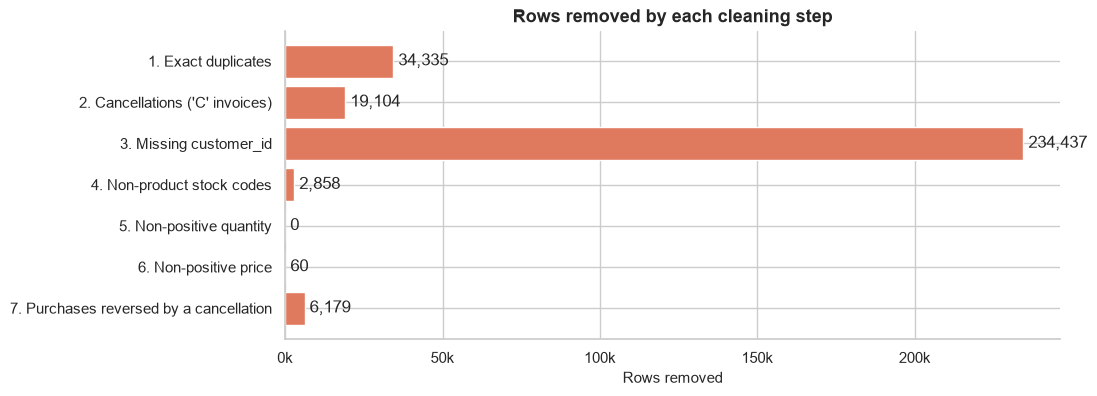

Clean transactions: 770,398 rows (72.2% of raw), 5,839 customers, 36,329 invoices, 4,611 products
Cancellation lines kept for features: 17,586


In [8]:
# Final types and derived columns
df["customer_id"] = df.customer_id.astype(int)
cancellations["customer_id"] = cancellations.customer_id.astype(int)
df["revenue"] = df.quantity * df.price
df["description"] = df.description.str.strip()

fig, ax = plt.subplots(figsize=(10, 4))
plot_log = cleaning_log.iloc[1:]
ax.barh(plot_log.index[::-1], plot_log.rows_removed[::-1], color=ACCENT)
for y, v in enumerate(plot_log.rows_removed[::-1]):
    ax.text(v, y, f" {v:,}", va="center")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e3:.0f}k"))
style(ax, "Rows removed by each cleaning step", "Rows removed", None)
plt.show()

print(f"Clean transactions: {len(df):,} rows ({len(df) / len(raw):.1%} of raw), "
      f"{df.customer_id.nunique():,} customers, {df.invoice.nunique():,} invoices, "
      f"{df.stock_code.nunique():,} products")
print(f"Cancellation lines kept for features: {len(cancellations):,}")

In [9]:
# Largest remaining order lines (after removing reversed purchases)
df.nlargest(5, "revenue")[["invoice", "invoice_date", "customer_id", "description", "quantity", "price", "revenue"]]

,invoice,invoice_date,customer_id,description,quantity,price,revenue
228042,511465,2010-06-08 12:59:00,18008,PINK PAPER PARASOL,3500,2.550,"8,925.000"
873786,567423,2011-09-20 11:05:00,17450,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.060,"7,144.720"
686007,550461,2011-04-18 13:20:00,15749,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.100,"6,539.400"
379875,525968,2010-10-08 10:10:00,15838,ROTATING SILVER ANGELS T-LIGHT HLDR,3120,1.660,"5,179.200"
947062,573003,2011-10-27 12:11:00,14646,RABBIT NIGHT LIGHT,2400,2.080,"4,992.000"


**Takeaway:** missing customer IDs are the biggest issue, at roughly a fifth of all lines. Removing them is unavoidable for customer-level modelling, but it means our customer analyses describe *registered* customers only. Cancellations are kept separately as a behavioural signal instead of being thrown away, and purchases they reversed are removed so they don't inflate revenue. The largest remaining orders look like genuine wholesale purchases, so they stay in, and the skewed features are log-transformed later to stop them from dominating.

# 3. Exploratory data analysis

**Question:** how does the business behave over time, across countries, across products and across the week?

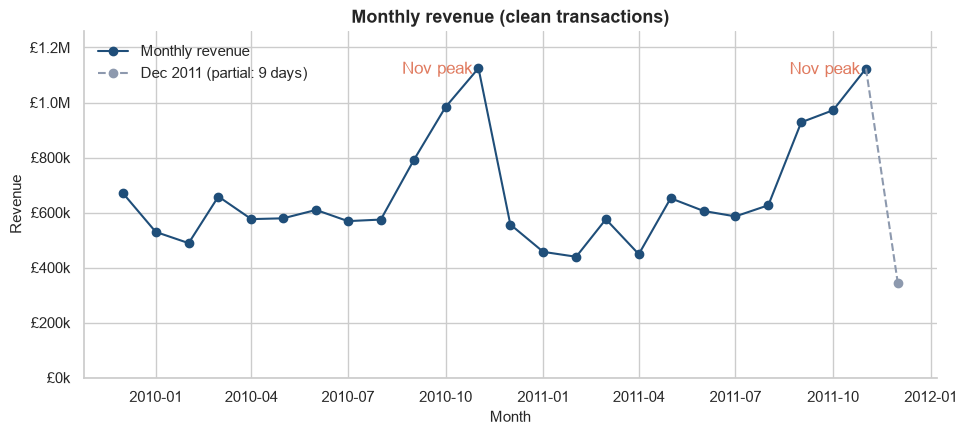

Revenue Jan-Nov 2011 vs Jan-Nov 2010: -0.9%


In [10]:
# Monthly revenue; the last month (Dec 2011) only contains 9 days
monthly = df.set_index("invoice_date").resample("MS").revenue.sum()
partial_month = monthly.index[-1]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index[:-1], monthly.values[:-1], marker="o", color=MAIN, label="Monthly revenue")
ax.plot(monthly.index[-2:], monthly.values[-2:], ls="--", color=PALETTE[6])
ax.plot(monthly.index[-1:], monthly.values[-1:], marker="o", ls="--", color=PALETTE[6], label="Dec 2011 (partial: 9 days)")
for peak in monthly.loc[monthly.index.month == 11].index:
    ax.annotate("Nov peak", (peak, monthly[peak]), textcoords="offset points", xytext=(-55, -4), color=ACCENT)
ax.set_ylim(0, monthly.max() * 1.12)
ax.yaxis.set_major_formatter(gbp)
style(ax, "Monthly revenue (clean transactions)", "Month", "Revenue")
ax.legend()
plt.show()

yoy = monthly["2011-01":"2011-11"].sum() / monthly["2010-01":"2010-11"].sum() - 1
print(f"Revenue Jan-Nov 2011 vs Jan-Nov 2010: {yoy:+.1%}")

**Insight:** revenue is strongly seasonal and flat year over year. It climbs from September and peaks in November both years, as retailers stock up for Christmas, then drops sharply. Any model that predicts the *next 90 days* has to account for this seasonality (see the churn section).

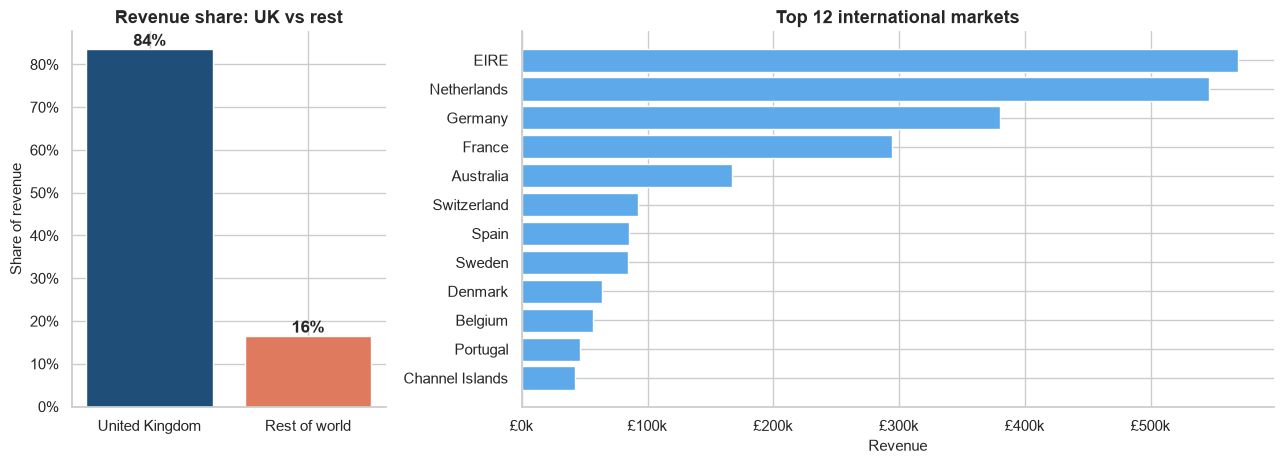

41 countries; UK share of revenue = 83.5%


In [11]:
country_rev = df.groupby("country").revenue.sum().sort_values(ascending=False)
uk_share = country_rev["United Kingdom"] / country_rev.sum()
top_intl = country_rev.drop("United Kingdom").head(12)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 2.4]})
axes[0].bar(["United Kingdom", "Rest of world"], [uk_share, 1 - uk_share], color=[MAIN, ACCENT])
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
for x, v in enumerate([uk_share, 1 - uk_share]):
    axes[0].text(x, v, f"{v:.0%}", ha="center", va="bottom", fontweight="bold")
style(axes[0], "Revenue share: UK vs rest", None, "Share of revenue")

axes[1].barh(top_intl.index[::-1], top_intl.values[::-1], color=PALETTE[5])
axes[1].xaxis.set_major_formatter(gbp)
style(axes[1], "Top 12 international markets", "Revenue", None)
plt.tight_layout()
plt.show()
print(f"{df.country.nunique()} countries; UK share of revenue = {uk_share:.1%}")

**Insight:** the shop is essentially a UK business, with the UK bringing in about 84% of revenue. Abroad, revenue is concentrated in a few nearby markets (Ireland/EIRE, Netherlands, Germany, France). The country mix is very lopsided, so a simple `is_uk` flag is a more sensible model feature than one-hot encoding 40 countries.

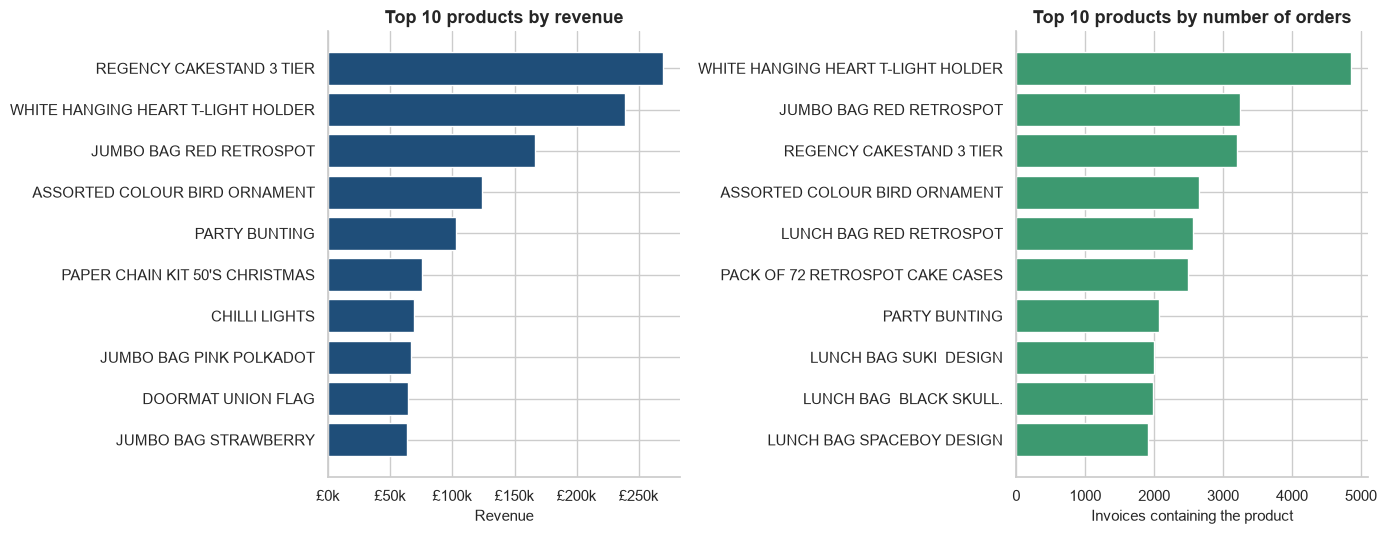

In [12]:
# Use the most frequent description per stock code as its display name
name_map = (df.groupby("stock_code").description
              .agg(lambda s: s.mode().iat[0] if s.notna().any() else "UNKNOWN"))

prod = (df.groupby("stock_code")
          .agg(revenue=("revenue", "sum"), quantity=("quantity", "sum"), invoices=("invoice", "nunique")))
prod["name"] = name_map.reindex(prod.index).str.slice(0, 34)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
top_rev = prod.nlargest(10, "revenue")
axes[0].barh(top_rev.name[::-1], top_rev.revenue[::-1], color=MAIN)
axes[0].xaxis.set_major_formatter(gbp)
style(axes[0], "Top 10 products by revenue", "Revenue", None)

top_inv = prod.nlargest(10, "invoices")
axes[1].barh(top_inv.name[::-1], top_inv.invoices[::-1], color=GOOD)
style(axes[1], "Top 10 products by number of orders", "Invoices containing the product", None)
plt.tight_layout()
plt.show()

**Insight:** a few home-decor staples (the *white hanging heart T-light holder*, *regency cakestand*, *jumbo bags*) top both rankings. Products that appear in many invoices are the ones that matter for basket analysis, which is why section 4 restricts itself to the most frequently ordered items.

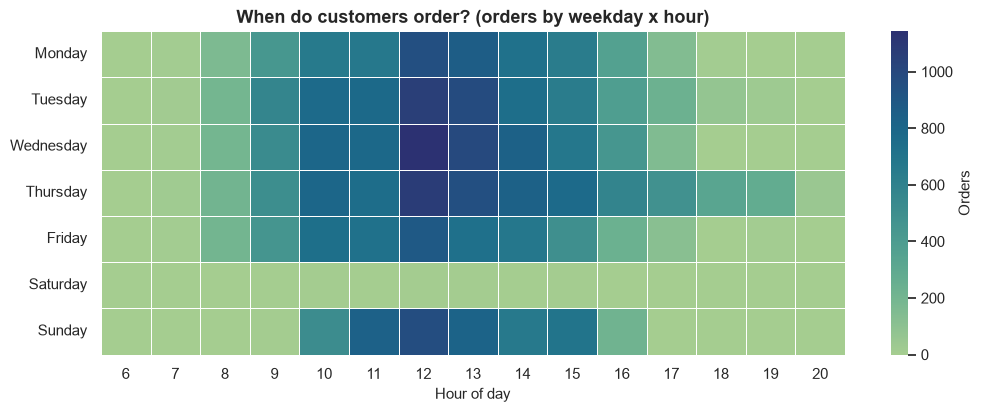

In [13]:
# Orders (distinct invoices) by weekday and hour
orders = df.drop_duplicates("invoice")[["invoice", "invoice_date"]]
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = (orders.assign(weekday=orders.invoice_date.dt.day_name(), hour=orders.invoice_date.dt.hour)
              .pivot_table(index="weekday", columns="hour", values="invoice", aggfunc="count", fill_value=0)
              .reindex(day_order, fill_value=0))

fig, ax = plt.subplots(figsize=(12, 4.2))
sns.heatmap(heat, cmap=SEQ_CMAP, linewidths=0.5, cbar_kws={"label": "Orders"}, ax=ax)
style(ax, "When do customers order? (orders by weekday x hour)", "Hour of day", "")
plt.show()

**Insight:** orders come in during UK office hours, peaking around 10:00-15:00 from Monday to Thursday, which fits a B2B wholesale audience. There are **no Saturday orders at all**, while Sunday orders bunch around midday and stop by about 16:00. Marketing e-mails and retention campaigns should therefore go out on weekday mornings.

**Section takeaway:** this is a seasonal, UK-centric, B2B-style business. Its revenue depends on a core assortment of best-sellers and on repeat customers, so understanding and retaining those customers is the main lever.

# 4. Market basket analysis (association rules)

**Question:** which products are bought together, and how could we use that for cross-selling?

**Approach.** One basket = one invoice. To keep FP-Growth fast and the rules meaningful, we only consider the **200 most frequently ordered products**. Each invoice becomes a row of True/False flags ("does the basket contain product X?").

**The three metrics in plain words**, for a rule *A → B*:
- **Support**: how common the combination is. *"A and B appear together in 2% of all baskets."*
- **Confidence**: how often the rule is right. *"Of the baskets that contain A, 60% also contain B."* (an estimate of P(B | A))
- **Lift**: how much more likely B is when A is in the basket than it is in general. Lift = confidence / support(B). Lift = 1 means no relationship, and lift = 10 means B is ten times more likely when A is present. Lift is the best metric for spotting *interesting* rules, because confidence alone favours products that are popular anyway.

In [14]:
N_TOP_PRODUCTS = 200
top_codes = prod.nlargest(N_TOP_PRODUCTS, "invoices").index

# Unique, readable column names for the basket matrix
labels = name_map.reindex(top_codes)
labels = labels.where(~labels.duplicated(keep=False), labels + " (" + labels.index + ")")

basket = (df[df.stock_code.isin(top_codes)]
            .drop_duplicates(["invoice", "stock_code"])
            .assign(flag=True)
            .pivot(index="invoice", columns="stock_code", values="flag")
            .notna()
            .rename(columns=labels))
print(f"Basket matrix: {basket.shape[0]:,} invoices x {basket.shape[1]} products "
      f"(avg {basket.sum(axis=1).mean():.1f} top products per basket)")

Basket matrix: 31,731 invoices x 200 products (avg 7.3 top products per basket)


In [15]:
t0 = time.time()
frequent = fpgrowth(basket, min_support=0.01, use_colnames=True, max_len=3)
rules = association_rules(frequent, num_itemsets=len(basket), metric="lift", min_threshold=1.5)
print(f"FP-Growth: {len(frequent):,} frequent itemsets, {len(rules):,} rules (lift >= 1.5) in {time.time() - t0:.1f}s")

# Readable rule strings
fmt = lambda s: " + ".join(sorted(s))
rules["antecedent"] = rules.antecedents.apply(fmt)
rules["consequent"] = rules.consequents.apply(fmt)

top_rules = (rules[rules.confidence >= 0.3]
               .sort_values("lift", ascending=False)
               .drop_duplicates(subset=["support", "lift"])       # drop mirrored A->B / B->A pairs
               .head(15))
top_rules[["antecedent", "consequent", "support", "confidence", "lift"]].reset_index(drop=True)

FP-Growth: 569 frequent itemsets, 1,006 rules (lift >= 1.5) in 0.3s


,antecedent,consequent,support,confidence,lift
0,GREEN REGENCY TEACUP AND SAUCER + REGENCY CAKE...,PINK REGENCY TEACUP AND SAUCER,0.012,0.729,30.946
1,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER + REGENCY CAKE...,0.012,0.499,30.946
2,GREEN REGENCY TEACUP AND SAUCER + ROSES REGENC...,PINK REGENCY TEACUP AND SAUCER,0.017,0.715,30.358
3,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER + ROSES REGENC...,0.017,0.711,30.358
4,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY...,0.017,0.567,30.305
5,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER + REGENCY CAKES...,0.012,0.399,30.107
6,PINK REGENCY TEACUP AND SAUCER + REGENCY CAKES...,GREEN REGENCY TEACUP AND SAUCER,0.012,0.888,30.107
7,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.020,0.838,28.409
8,PINK 3 PIECE MINI DOTS CUTLERY SET + RED 3 PIE...,BLUE 3 PIECE MINI DOTS CUTLERY SET,0.012,0.748,26.955
9,REGENCY CAKESTAND 3 TIER + ROSES REGENCY TEACU...,PINK REGENCY TEACUP AND SAUCER,0.011,0.634,26.923


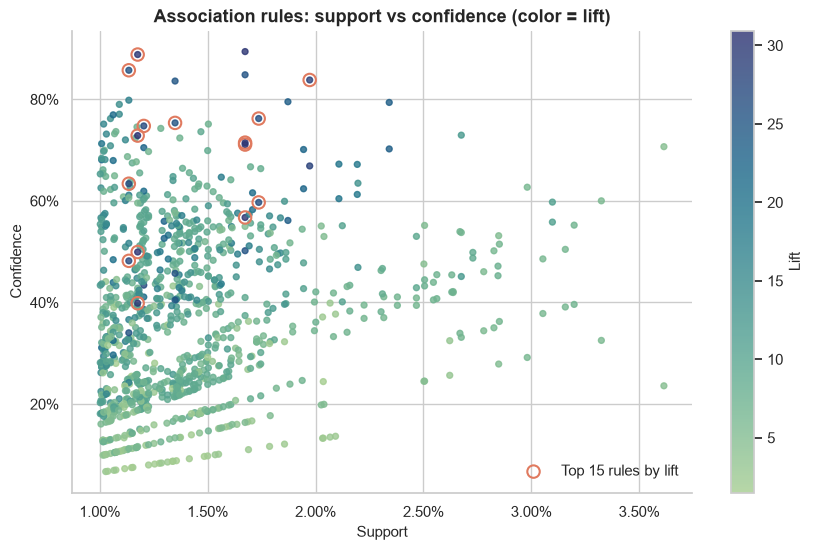

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(rules.support, rules.confidence, c=rules.lift, cmap=SEQ_CMAP, s=18, alpha=0.8)
ax.scatter(top_rules.support, top_rules.confidence, facecolors="none", edgecolors=ACCENT, s=80, lw=1.5,
           label="Top 15 rules by lift")
plt.colorbar(sc, ax=ax, label="Lift")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
style(ax, "Association rules: support vs confidence (color = lift)", "Support", "Confidence")
ax.legend(loc="lower right")
plt.show()

**Insight:** the strongest rules (very high lift) link **colour or design variants of the same product line**, such as tea-cup-and-saucer sets in different colours or the different *Regency* items. Customers collect a whole series. Most of these rules have low support but high confidence and lift, so they are niche but very reliable, which suits *"complete the set"* recommendations.

In [17]:
# A business view: the best "if they buy X, recommend Y" suggestion for the 8 most popular items
popular = labels.reindex(prod.nlargest(8, "invoices").index).tolist()
single = rules[rules.antecedents.apply(len) == 1]
recs = (single[single.antecedent.isin(popular)]
          .sort_values("confidence", ascending=False)
          .groupby("antecedent").head(1)
          [["antecedent", "consequent", "confidence", "lift"]]
          .reset_index(drop=True))
recs

,antecedent,consequent,confidence,lift
0,LUNCH BAG SUKI DESIGN,LUNCH BAG RED RETROSPOT,0.486,6.016
1,LUNCH BAG RED RETROSPOT,LUNCH BAG PINK POLKADOT,0.396,6.840
2,PACK OF 72 RETROSPOT CAKE CASES,60 TEATIME FAIRY CAKE CASES,0.363,6.544
3,JUMBO BAG RED RETROSPOT,JUMBO BAG PINK POLKADOT,0.325,5.872
4,ASSORTED COLOUR BIRD ORNAMENT,WHITE HANGING HEART T-LIGHT HOLDER,0.244,1.594
5,WHITE HANGING HEART T-LIGHT HOLDER,RED HANGING HEART T-LIGHT HOLDER,0.236,4.612
6,PARTY BUNTING,SPOTTY BUNTING,0.188,5.912
7,REGENCY CAKESTAND 3 TIER,ROSES REGENCY TEACUP AND SAUCER,0.177,5.314


**Takeaway:** association rules give us a ready-made, explainable cross-sell engine: *"customers who bought this also bought..."*. High-lift rules mostly reflect product *families*. The practical uses are bundles and "complete the collection" prompts at checkout, and keeping complementary items stocked together.

# 5. Customer segmentation (clustering + PCA)

**Question:** can customers be grouped into a few distinct, actionable segments based on their purchase behaviour?

**Features per customer** (snapshot = the day after the last transaction):

| Feature | Meaning |
|---|---|
| `recency` | days since the last purchase |
| `frequency` | number of distinct invoices |
| `monetary` | total revenue (£) |
| `avg_basket` | average invoice value (£) |
| `tenure` | days since the first purchase |
| `distinct_products` | number of different products bought |
| `return_rate` | share of the customer's invoices that were cancellations |

The same feature function is reused in sections 6 and 7, and there it only sees data *before* a cutoff date.

In [18]:
def customer_features(tx, cancels, snapshot, extended=False):
    # Behavioural features per customer, using ONLY rows strictly before `snapshot`
    tx = tx[tx.invoice_date < snapshot]
    cancels = cancels[cancels.invoice_date < snapshot]

    inv = (tx.groupby(["customer_id", "invoice"])
             .agg(date=("invoice_date", "min"), value=("revenue", "sum"))
             .reset_index())
    g = inv.groupby("customer_id")
    first, last = g.date.min(), g.date.max()

    f = pd.DataFrame({
        "recency": (snapshot - last).dt.days,
        "frequency": g.size(),
        "monetary": g.value.sum(),
        "tenure": (snapshot - first).dt.days,
        "distinct_products": tx.groupby("customer_id").stock_code.nunique(),
    })
    f["avg_basket"] = f.monetary / f.frequency
    n_cancel = cancels.groupby("customer_id").invoice.nunique().reindex(f.index, fill_value=0)
    f["return_rate"] = n_cancel / (f.frequency + n_cancel)

    if extended:
        # Extra features for the predictive models
        recent = inv[inv.date >= snapshot - pd.Timedelta(days=90)].groupby("customer_id")
        f["frequency_90d"] = recent.size().reindex(f.index, fill_value=0)
        f["monetary_90d"] = recent.value.sum().reindex(f.index, fill_value=0.0)
        span = (last - first).dt.days
        f["avg_days_between"] = np.where(f.frequency > 1, span / (f.frequency - 1).clip(lower=1), f.tenure)
        main_country = tx.groupby("customer_id").country.agg(lambda s: s.mode().iat[0])
        f["is_uk"] = (main_country == "United Kingdom").astype(int)
    return f


SNAPSHOT = df.invoice_date.max().normalize() + pd.Timedelta(days=1)
customers = customer_features(df, cancellations, SNAPSHOT)
SEG_FEATURES = ["recency", "frequency", "monetary", "avg_basket", "tenure", "distinct_products", "return_rate"]
customers = customers[SEG_FEATURES]
print(f"{len(customers):,} customers, snapshot {SNAPSHOT:%Y-%m-%d}")
customers.describe().T

5,839 customers, snapshot 2011-12-10


,count,mean,std,min,25%,50%,75%,max
recency,"5,839.000",199.906,208.608,0.000,25.000,95.000,379.000,738.000
frequency,"5,839.000",6.222,12.634,1.000,1.000,3.000,7.000,369.000
monetary,"5,839.000","2,820.185","13,875.951",2.900,336.245,851.010,"2,206.485","579,128.640"
avg_basket,"5,839.000",360.496,470.495,2.900,174.963,275.005,409.275,"12,425.450"
tenure,"5,839.000",473.688,223.109,0.000,311.000,529.000,666.000,738.000
distinct_products,"5,839.000",81.872,116.059,1.000,19.000,45.000,103.000,"2,506.000"
return_rate,"5,839.000",0.112,0.162,0.000,0.000,0.000,0.200,0.800


Log-transformed features: ['monetary', 'avg_basket', 'frequency', 'distinct_products', 'return_rate']


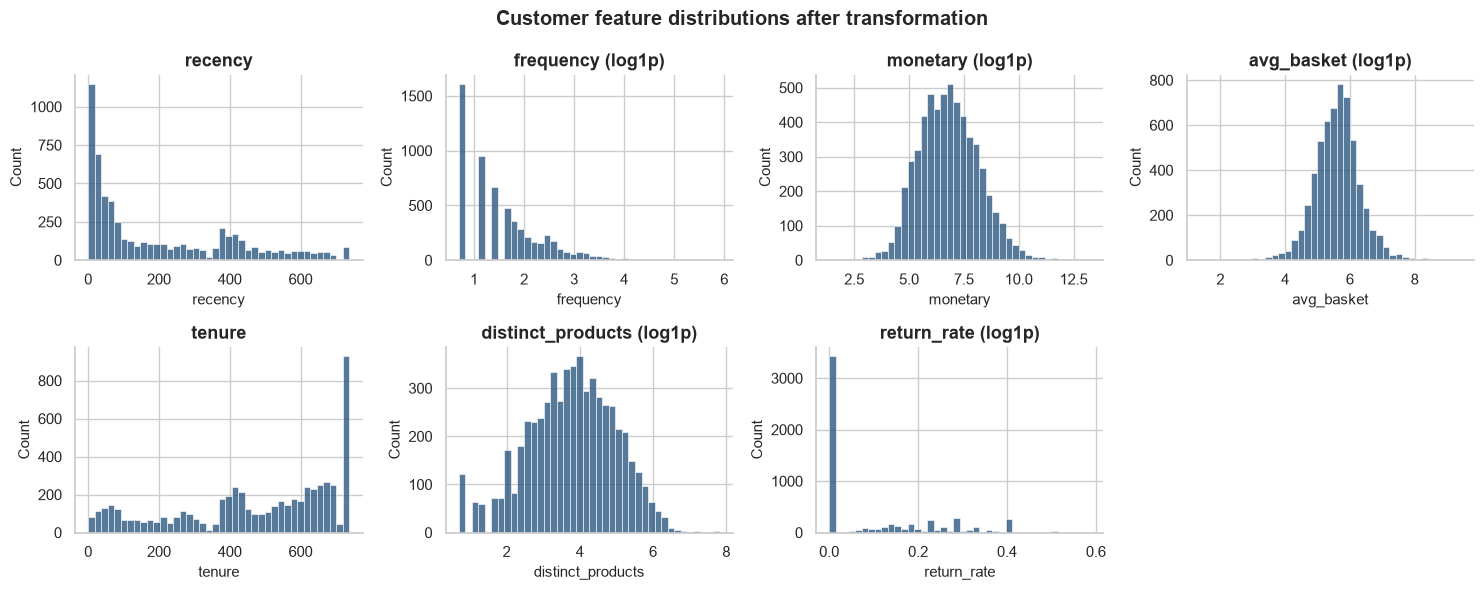

In [19]:
# Skewness decides which features get a log transform (|skew| > 1)
skew = customers.skew().sort_values(ascending=False)
LOG_FEATURES = skew[skew.abs() > 1].index.tolist()
print("Log-transformed features:", LOG_FEATURES)

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, col in zip(axes.ravel(), SEG_FEATURES):
    sns.histplot(np.log1p(customers[col]) if col in LOG_FEATURES else customers[col], bins=40, ax=ax, color=MAIN)
    style(ax, col + (" (log1p)" if col in LOG_FEATURES else ""), None, None)
axes.ravel()[-1].axis("off")
fig.suptitle("Customer feature distributions after transformation", fontweight="bold")
plt.tight_layout()
plt.show()

In [20]:
# Preprocessing pipeline: log1p on skewed features, then standardise everything

seg_prep = Pipeline([
    ("log", ColumnTransformer([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), LOG_FEATURES)],
                              remainder="passthrough", verbose_feature_names_out=False)),
    ("scale", StandardScaler()),
]).set_output(transform="pandas")
X_seg = seg_prep.fit_transform(customers)[SEG_FEATURES]
X_seg.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
recency,0.000,1.000,-0.958,2.580
frequency,0.000,1.000,-1.057,5.421
monetary,0.000,1.000,-3.945,4.701
avg_basket,0.000,1.000,-5.821,5.255
tenure,0.000,1.000,-2.123,1.185
distinct_products,0.000,1.000,-2.541,3.361
return_rate,-0.000,1.000,-0.714,3.645


### 5.1 K-Means: choosing k

The elbow method looks for the k after which adding clusters stops reducing the within-cluster sum of squares (inertia) by much. The silhouette score (from -1 to 1, higher is better) measures how well each customer fits its own cluster compared to the nearest other one.

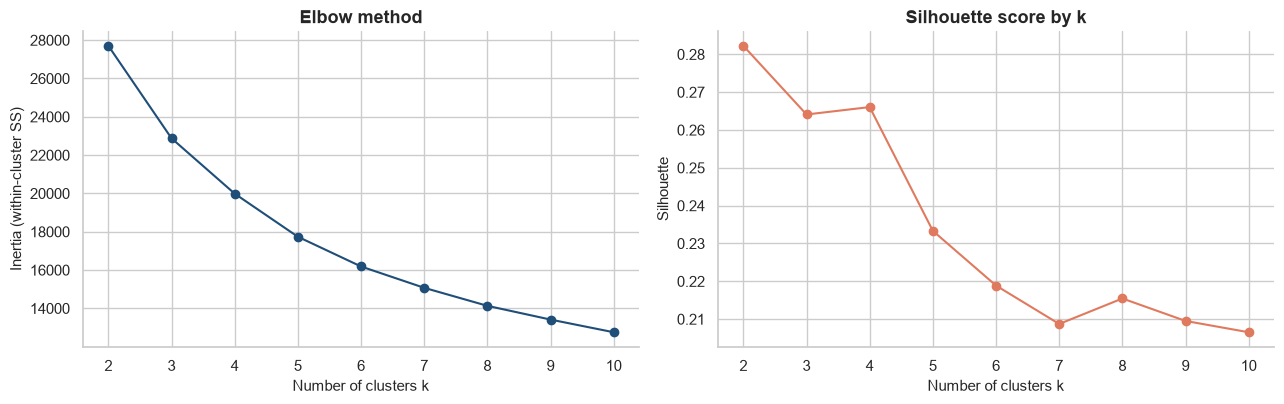

k,2,3,4,5,6,7,8,9,10
inertia,"27,705.540","22,875.940","19,986.463","17,737.052","16,185.444","15,071.254","14,131.548","13,413.322","12,752.206"
silhouette,0.282,0.264,0.266,0.233,0.219,0.209,0.215,0.210,0.207


In [21]:
K_RANGE = range(2, 11)
k_scores = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_seg)
    k_scores.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X_seg, km.labels_)})
k_scores = pd.DataFrame(k_scores).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(k_scores.index, k_scores.inertia, marker="o", color=MAIN)
style(axes[0], "Elbow method", "Number of clusters k", "Inertia (within-cluster SS)")
axes[1].plot(k_scores.index, k_scores.silhouette, marker="o", color=ACCENT)
style(axes[1], "Silhouette score by k", "Number of clusters k", "Silhouette")
plt.tight_layout()
plt.show()
k_scores.T

In [22]:
# k = 2 usually wins on silhouette but only splits "good vs bad" customers, which is too coarse to act on.
# We pick the best silhouette within the actionable range 3-6.
K_BEST = int(k_scores.loc[3:6, "silhouette"].idxmax())
print(f"Chosen k = {K_BEST} (silhouette {k_scores.loc[K_BEST, 'silhouette']:.3f})")

kmeans = KMeans(n_clusters=K_BEST, n_init=20, random_state=SEED).fit(X_seg)
customers["km_cluster"] = kmeans.labels_

Chosen k = 4 (silhouette 0.266)


### 5.2 Agglomerative clustering (Ward)

Ward linkage merges, at each step, the two clusters whose union increases the within-cluster variance the least. That is the same objective K-Means optimises, built bottom-up. The dendrogram uses a random sample of 600 customers to stay readable. The clustering itself runs on all customers.

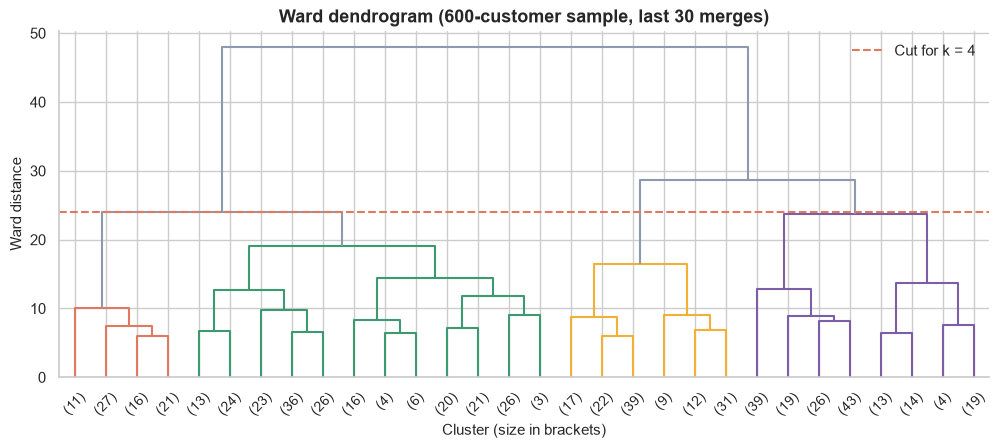

In [23]:
sample_idx = rng.choice(len(X_seg), size=600, replace=False)
Z = linkage(X_seg.iloc[sample_idx], method="ward")

fig, ax = plt.subplots(figsize=(12, 4.5))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=Z[-(K_BEST - 1), 2], ax=ax,
           above_threshold_color=PALETTE[6])
ax.axhline(Z[-(K_BEST - 1), 2], ls="--", color=ACCENT, label=f"Cut for k = {K_BEST}")
style(ax, "Ward dendrogram (600-customer sample, last 30 merges)", "Cluster (size in brackets)", "Ward distance")
ax.legend()
plt.show()

agglo = AgglomerativeClustering(n_clusters=K_BEST, linkage="ward").fit(X_seg)
customers["agg_cluster"] = agglo.labels_

In [24]:
# Compare the two clusterings
comparison = pd.DataFrame({
    "Silhouette (higher = better)": [silhouette_score(X_seg, customers.km_cluster),
                                      silhouette_score(X_seg, customers.agg_cluster)],
    "Davies-Bouldin (lower = better)": [davies_bouldin_score(X_seg, customers.km_cluster),
                                         davies_bouldin_score(X_seg, customers.agg_cluster)],
}, index=["K-Means", "Agglomerative (Ward)"])
ari = adjusted_rand_score(customers.km_cluster, customers.agg_cluster)
print(f"Adjusted Rand Index between K-Means and Ward: {ari:.3f} (1 = identical partitions, 0 = random agreement)")
comparison

Adjusted Rand Index between K-Means and Ward: 0.435 (1 = identical partitions, 0 = random agreement)


,Silhouette (higher = better),Davies-Bouldin (lower = better)
K-Means,0.266,1.308
Agglomerative (Ward),0.191,1.535


### 5.3 PCA: what drives the differences between customers?

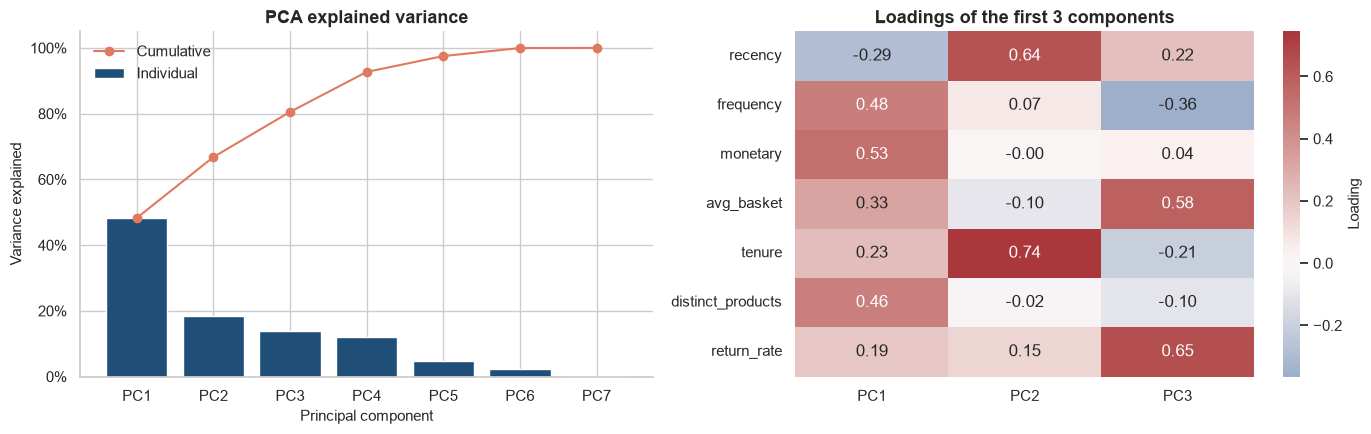

PC1 + PC2 explain 66.8% of the variance


In [25]:
pca = PCA(random_state=SEED).fit(X_seg)
evr = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
pcs = [f"PC{i + 1}" for i in range(len(evr))]
axes[0].bar(pcs, evr, color=MAIN, label="Individual")
axes[0].plot(pcs, np.cumsum(evr), marker="o", color=ACCENT, label="Cumulative")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].legend()
style(axes[0], "PCA explained variance", "Principal component", "Variance explained")

loadings = pd.DataFrame(pca.components_[:3].T, index=SEG_FEATURES, columns=pcs[:3])
sns.heatmap(loadings, annot=True, fmt=".2f", cmap=DIV_CMAP, center=0, ax=axes[1], cbar_kws={"label": "Loading"})
style(axes[1], "Loadings of the first 3 components", None, None)
plt.tight_layout()
plt.show()
print(f"PC1 + PC2 explain {evr[:2].sum():.1%} of the variance")

**Reading the loadings.**
- **PC1** (about half of the variance) loads positively on frequency, monetary and distinct products, and negatively on recency. It is an overall **"customer value / engagement"** axis.
- **PC2** is driven by **tenure and recency** together, so it is a **lifecycle** axis. High values are old accounts that have not ordered for a long time, low values are recently acquired customers.
- **PC3** captures **average basket size and return rate**, separating a few big orders (often with returns) from many small ones.

In [26]:
# Profile the K-Means clusters on the ORIGINAL scale and give them business names
def name_segments(profile):
    # Rule-based naming using medians relative to the overall customer base
    overall = customers[SEG_FEATURES].median()
    names = {}
    for c, row in profile.iterrows():
        recent = row.recency <= overall.recency
        frequent = row.frequency > overall.frequency
        new = row.tenure <= overall.tenure * 0.6
        if recent and frequent:
            names[c] = "Champions"
        elif recent and new:
            names[c] = "New Customers"
        elif recent:
            names[c] = "Promising"
        elif frequent or row.monetary > overall.monetary:
            names[c] = "At Risk"
        else:
            names[c] = "Lost"
    # Ensure names are unique (append the rank if two clusters get the same name)
    s = pd.Series(names)
    for n in s[s.duplicated(keep=False)].unique():
        idx = profile.loc[s[s == n].index].sort_values("monetary", ascending=False).index
        for i, c in enumerate(idx):
            s[c] = f"{n} {'(high value)' if i == 0 else '(low value)'}"
    return s


profile = customers.groupby("km_cluster")[SEG_FEATURES].median()
seg_names = name_segments(profile)
customers["segment"] = customers.km_cluster.map(seg_names)

seg_profile = (customers.groupby("segment")
                 .agg(customers=("recency", "size"), **{f"median_{c}": (c, "median") for c in SEG_FEATURES},
                      total_revenue=("monetary", "sum")))
seg_profile["share_customers"] = seg_profile.customers / seg_profile.customers.sum()
seg_profile["share_revenue"] = seg_profile.total_revenue / seg_profile.total_revenue.sum()
SEG_ORDER = seg_profile.sort_values("median_monetary", ascending=False).index.tolist()
SEG_COLORS = dict(zip(SEG_ORDER, PALETTE))
seg_profile.loc[SEG_ORDER]

,customers,median_recency,median_frequency,median_monetary,median_avg_basket,median_tenure,median_distinct_products,median_return_rate,total_revenue,share_customers,share_revenue
segment,,,,,,,,,,,
Champions,1984,31.000,9.000,"3,187.620",341.213,662.500,128.000,0.125,"13,897,263.080",0.340,0.844
At Risk,904,219.500,3.000,865.130,302.452,499.000,37.000,0.380,"964,770.240",0.155,0.059
New Customers,1495,50.000,2.000,506.040,241.235,172.000,29.000,0.000,"1,017,416.920",0.256,0.062
Lost,1456,435.000,1.000,299.575,184.418,561.000,19.000,0.000,"587,609.360",0.249,0.036


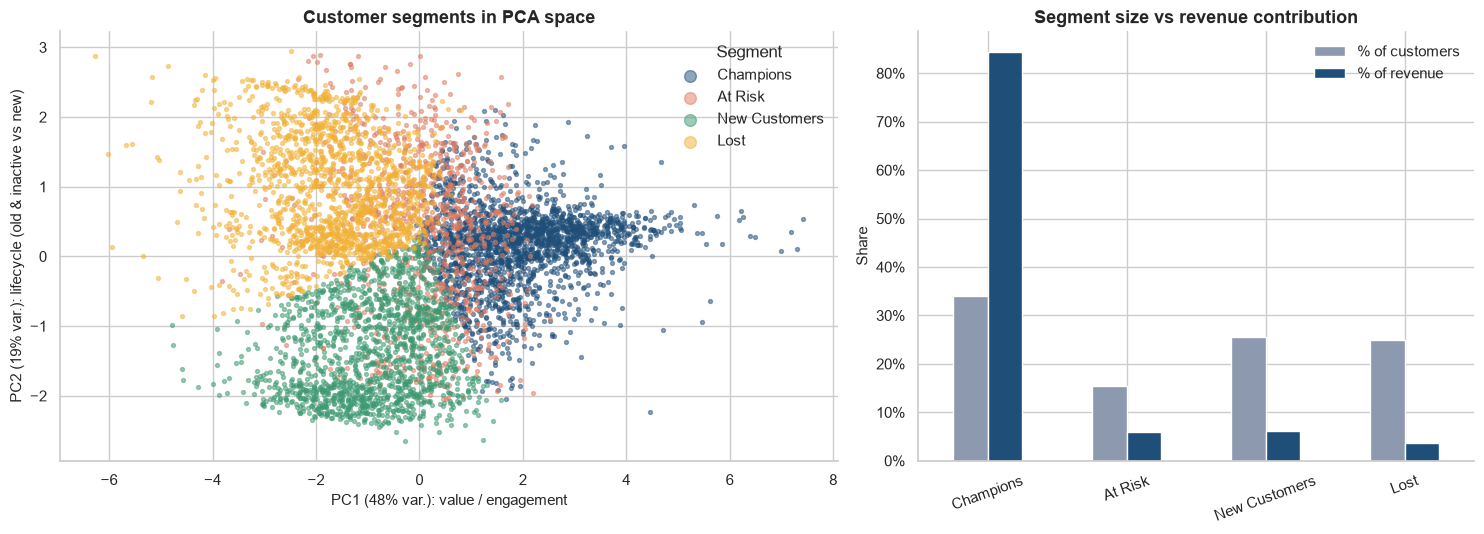

In [27]:
proj = pca.transform(X_seg)[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
for seg in SEG_ORDER:
    m = (customers.segment == seg).values
    axes[0].scatter(proj[m, 0], proj[m, 1], s=8, alpha=0.5, color=SEG_COLORS[seg], label=seg)
axes[0].legend(markerscale=3, title="Segment")
style(axes[0], "Customer segments in PCA space", f"PC1 ({evr[0]:.0%} var.): value / engagement",
      f"PC2 ({evr[1]:.0%} var.): lifecycle (old & inactive vs new)")

share = seg_profile.loc[SEG_ORDER, ["share_customers", "share_revenue"]]
share.columns = ["% of customers", "% of revenue"]
share.plot.bar(ax=axes[1], color=[PALETTE[6], MAIN], rot=20)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
style(axes[1], "Segment size vs revenue contribution", "", "Share")
plt.tight_layout()
plt.show()

**Takeaway:** four segments emerge, laid out along the two PCA axes: value (left to right) and lifecycle (bottom to top). K-Means gives better silhouette and Davies-Bouldin scores than Ward, and the two methods agree only **moderately** (ARI ≈ 0.44). Customer behaviour forms a continuum rather than well-separated blobs, so the segment *boundaries* should be treated as a business convention, not a natural law. The business picture is a strong Pareto pattern:
- **Champions** (about a third of customers) bring in **over 80% of revenue**: recent, frequent, broad-assortment buyers.
- **At Risk** customers spent above the median but have not ordered for about 7 months, and they have the **highest return rate**. Unhappy returns may be part of why they left, which makes them the first win-back target.
- **New Customers** were acquired recently (tenure of about 6 months) and need onboarding to become repeat buyers.
- **Lost** customers are numerous but contribute little, so expensive retention spending on them is hard to justify.

# 6. Churn prediction (classification)

**Question:** using only what we know today, which active customers will **not buy at all in the next 90 days**?

### 6.1 Time-based design (and why it avoids leakage)

A random train/test split of customers would be wrong here. Features like *recency* computed on the full dataset would already "see" the future purchases we are trying to predict. Instead we simulate how the model would actually be used:

- Pick a **cutoff date**. **Features** are computed **only from transactions strictly before the cutoff**.
- The **label** looks only at the **90 days after the cutoff**: `churn = 1` if the customer makes no purchase in that window.
- **Cohort:** customers who bought at least once in the 12 months before the cutoff. A customer who left two years ago is not a meaningful "churn" case.
- **Out-of-time validation:** the model is **trained** on cutoff `T_train` and **tested** on a later cutoff `T_test = T_train + 90 days`. The training labels end exactly where the test features end, so no information from the test period leaks into training. This also tests whether the model still works on a later, unseen period.
- All preprocessing (log transform, scaling) sits **inside sklearn Pipelines**, so in cross-validation it is fitted on the training folds only.

In [28]:
HORIZON = pd.Timedelta(days=90)
END = df.invoice_date.max().normalize() + pd.Timedelta(days=1)    # day after the last transaction
TEST_CUTOFF = END - HORIZON
TRAIN_CUTOFF = TEST_CUTOFF - HORIZON


def build_dataset(cutoff):
    # Features before `cutoff`, labels from [cutoff, cutoff + 90 days)
    feats = customer_features(df, cancellations, cutoff, extended=True)
    feats = feats[feats.recency <= 365]                                   # active-customer cohort
    window = df[(df.invoice_date >= cutoff) & (df.invoice_date < cutoff + HORIZON)]
    future_spend = window.groupby("customer_id").revenue.sum().reindex(feats.index, fill_value=0.0)
    return feats, (future_spend == 0).astype(int).rename("churn"), future_spend.rename("future_spend")


X_train, y_train, spend_train = build_dataset(TRAIN_CUTOFF)
X_test, y_test, spend_test = build_dataset(TEST_CUTOFF)
FEATURES = X_train.columns.tolist()

pd.DataFrame({
    "feature window": [f"< {TRAIN_CUTOFF:%Y-%m-%d}", f"< {TEST_CUTOFF:%Y-%m-%d}"],
    "label window": [f"{TRAIN_CUTOFF:%Y-%m-%d} to {TEST_CUTOFF - pd.Timedelta(days=1):%Y-%m-%d}",
                     f"{TEST_CUTOFF:%Y-%m-%d} to {END - pd.Timedelta(days=1):%Y-%m-%d}"],
    "customers": [len(X_train), len(X_test)],
    "churn rate": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])

,feature window,label window,customers,churn rate
train,< 2011-06-13,2011-06-13 to 2011-09-10,4313,0.641
test,< 2011-09-11,2011-09-11 to 2011-12-09,4299,0.492


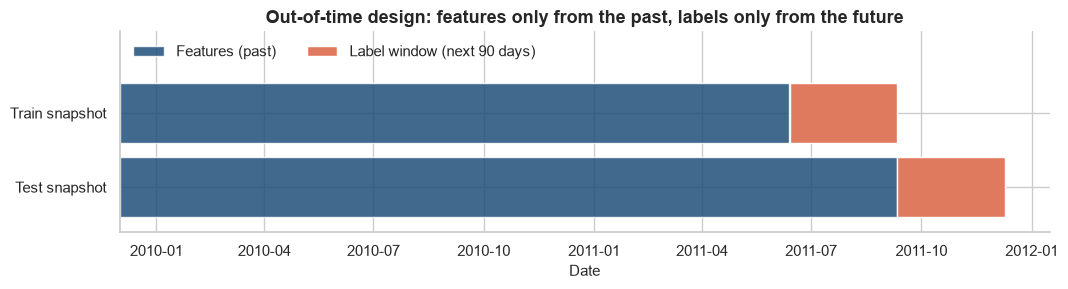

In [29]:
# Visual timeline of the two snapshots
fig, ax = plt.subplots(figsize=(12, 2.6))
start = df.invoice_date.min()
for y, (cut, name) in enumerate([(TEST_CUTOFF, "Test"), (TRAIN_CUTOFF, "Train")]):
    ax.barh(y, (cut - start).days, left=start, color=MAIN, alpha=0.85, label="Features (past)" if y == 0 else None)
    ax.barh(y, HORIZON.days, left=cut, color=ACCENT, label="Label window (next 90 days)" if y == 0 else None)
ax.set_yticks([0, 1], ["Test snapshot", "Train snapshot"])
ax.set_ylim(-0.6, 2.1)
ax.legend(loc="upper left", ncol=2)
style(ax, "Out-of-time design: features only from the past, labels only from the future", "Date", None)
plt.show()

### 6.2 Models

Every model is a Pipeline. The linear and probabilistic models get `log1p → StandardScaler`, because they are sensitive to skew and scale. Tree models get raw features, since they are invariant to monotonic transformations. Hyperparameters of the ensembles are tuned with `RandomizedSearchCV` on 5-fold `StratifiedKFold` inside the training snapshot, optimising **PR-AUC** (average precision). PR-AUC focuses on how well the positive (churn) class is ranked.

In [30]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
log_scale = [("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]   # all features are >= 0

models = {
    "Naive Bayes": Pipeline(log_scale + [("model", GaussianNB())]),
    "Logistic Regression": Pipeline(log_scale + [("model", LogisticRegression(max_iter=2000, C=1.0))]),
    "Decision Tree": Pipeline([("model", DecisionTreeClassifier(max_depth=5, min_samples_leaf=40, random_state=SEED))]),
}

# Random Forest: tuned with RandomizedSearchCV
rf_search = RandomizedSearchCV(
    Pipeline([("model", RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
    param_distributions={
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [4, 6, 8, 12, None],
        "model__min_samples_leaf": [5, 10, 20, 40],
        "model__max_features": ["sqrt", 0.5, 0.8],
    },
    n_iter=15, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=-1)

# HistGradientBoosting: tuned with RandomizedSearchCV
hgb_search = RandomizedSearchCV(
    Pipeline([("model", HistGradientBoostingClassifier(random_state=SEED))]),
    param_distributions={
        "model__learning_rate": [0.02, 0.05, 0.1],
        "model__max_iter": [100, 200, 400],
        "model__max_leaf_nodes": [7, 15, 31],
        "model__min_samples_leaf": [20, 50, 100],
        "model__l2_regularization": [0.0, 0.1, 1.0],
    },
    n_iter=20, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=-1)

t0 = time.time()
rf_search.fit(X_train, y_train)
hgb_search.fit(X_train, y_train)
print(f"Tuning done in {time.time() - t0:.0f}s")
print("RF  best params:", rf_search.best_params_, f"CV PR-AUC={rf_search.best_score_:.3f}")
print("HGB best params:", hgb_search.best_params_, f"CV PR-AUC={hgb_search.best_score_:.3f}")

models["Random Forest"] = rf_search.best_estimator_
models["HistGradientBoosting"] = hgb_search.best_estimator_

Tuning done in 9s
RF  best params: {'model__n_estimators': 200, 'model__min_samples_leaf': 40, 'model__max_features': 'sqrt', 'model__max_depth': None} CV PR-AUC=0.862
HGB best params: {'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 7, 'model__max_iter': 100, 'model__learning_rate': 0.02, 'model__l2_regularization': 0.1} CV PR-AUC=0.861


In [31]:
# Stacking ensemble: tuned RF + tuned HGB + Logistic Regression, combined by a logistic meta-model
models["Stacking (LR+RF+HGB)"] = StackingClassifier(
    estimators=[("lr", clone(models["Logistic Regression"])),
                ("rf", clone(models["Random Forest"])),
                ("hgb", clone(models["HistGradientBoosting"]))],
    final_estimator=LogisticRegression(max_iter=1000),
    stack_method="predict_proba", cv=cv, n_jobs=-1)

# Cross-validated scores on the TRAIN snapshot (used for model selection, the test set stays untouched)
cv_rows = {}
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision"], n_jobs=-1)
    cv_rows[name] = {"CV ROC-AUC": res["test_roc_auc"].mean(), "CV PR-AUC": res["test_average_precision"].mean(),
                     "CV PR-AUC std": res["test_average_precision"].std()}
cv_table = pd.DataFrame(cv_rows).T.sort_values("CV PR-AUC", ascending=False)
cv_table

,CV ROC-AUC,CV PR-AUC,CV PR-AUC std
Stacking (LR+RF+HGB),0.809,0.862,0.008
Random Forest,0.809,0.862,0.009
HistGradientBoosting,0.808,0.861,0.007
Logistic Regression,0.803,0.861,0.010
Naive Bayes,0.799,0.856,0.005
Decision Tree,0.786,0.835,0.008


In [32]:
# Fit every model on the full training snapshot and evaluate on the later (out-of-time) test snapshot
test_proba, rows = {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    test_proba[name] = p
    pred = (p >= 0.5).astype(int)
    rows[name] = {"ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p),
                  "Precision@0.5": precision_score(y_test, pred), "Recall@0.5": recall_score(y_test, pred),
                  "F1@0.5": f1_score(y_test, pred)}

results = pd.DataFrame(rows).T.loc[cv_table.index]
BEST = cv_table.index[0]     # selected on CV, not on the test set
print(f"Selected model (best CV PR-AUC): {BEST}")
results.style.format("{:.3f}").highlight_max(color="#cfe3f5")

Selected model (best CV PR-AUC): Stacking (LR+RF+HGB)


,ROC-AUC,PR-AUC,Precision@0.5,Recall@0.5,F1@0.5
Stacking (LR+RF+HGB),0.765,0.719,0.615,0.892,0.728
Random Forest,0.764,0.713,0.610,0.895,0.725
HistGradientBoosting,0.766,0.720,0.609,0.903,0.728
Logistic Regression,0.760,0.721,0.611,0.891,0.725
Naive Bayes,0.757,0.724,0.633,0.817,0.713
Decision Tree,0.756,0.702,0.627,0.850,0.722


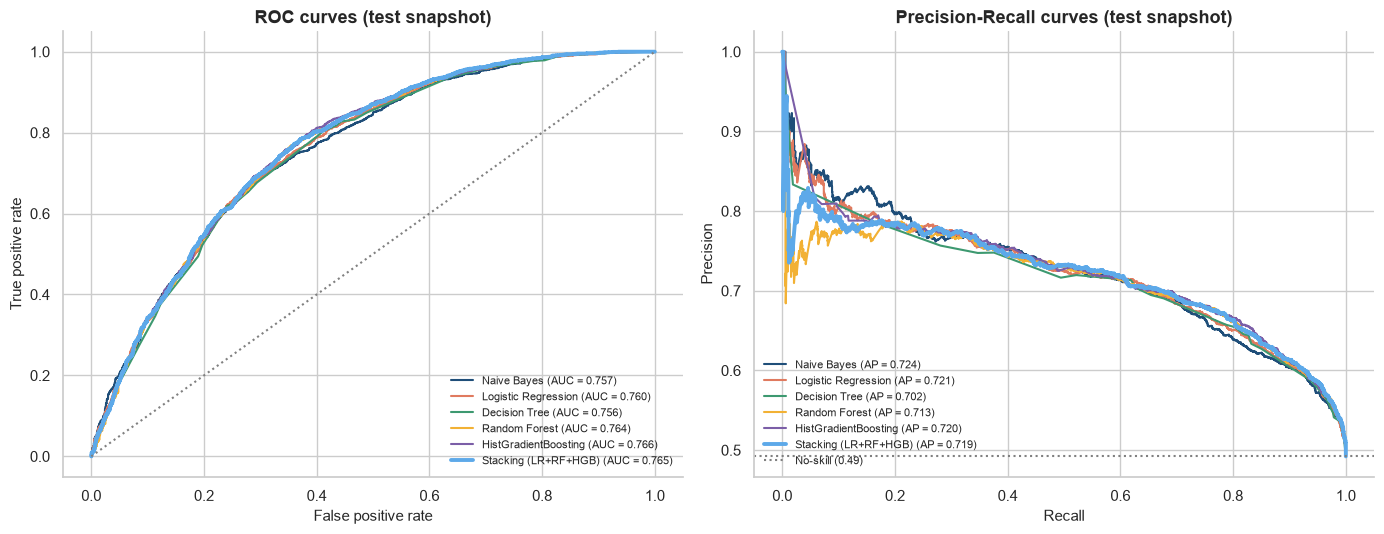

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for (name, p), color in zip(test_proba.items(), PALETTE):
    lw = 2.8 if name == BEST else 1.5
    fpr, tpr, _ = roc_curve(y_test, p)
    prc, rcl, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=color, lw=lw, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
    axes[1].plot(rcl, prc, color=color, lw=lw, label=f"{name} (AP = {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], ls=":", color="grey")
axes[1].axhline(y_test.mean(), ls=":", color="grey", label=f"No-skill ({y_test.mean():.2f})")
style(axes[0], "ROC curves (test snapshot)", "False positive rate", "True positive rate")
style(axes[1], "Precision-Recall curves (test snapshot)", "Recall", "Precision")
axes[1].legend(fontsize=8, loc="lower left")
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

### 6.3 Choosing the decision threshold

The default threshold of 0.5 is arbitrary. The trade-off is:
- **lower threshold:** we catch more churners (higher recall), but we also contact many customers who would have stayed anyway (lower precision, wasted vouchers and annoyed customers);
- **higher threshold:** the contact list is shorter and more precise, but more churners slip through.

There is one complication: **the churn rate depends on the season**. In the training label window (summer) it is much higher than in the test window (the run-up to Christmas, when even occasional buyers come back; see the table in 6.1). Criteria such as F1/F2 or "probability > 0.5" depend on that base rate, so a threshold tuned on summer data would flag almost everyone in autumn.

We therefore use **Youden's J = TPR - FPR** (recall on churners minus the false-alarm rate on loyal customers). It weighs both error types equally and does **not depend on the class balance**, so it transfers between seasons. The threshold is chosen on **out-of-fold predictions from the training snapshot**, never on the test set, and then applied unchanged to the test snapshot. If campaign costs were known, a profit-based threshold would replace it (see next steps).

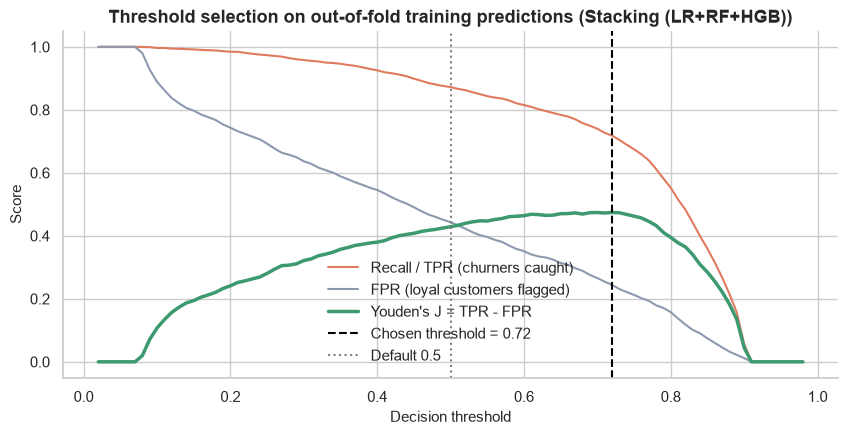

In [34]:
oof = cross_val_predict(clone(models[BEST]), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
thresholds = np.linspace(0.02, 0.98, 97)
tpr = np.array([recall_score(y_train, oof >= t) for t in thresholds])                              # churners caught
fpr = np.array([((oof >= t) & (y_train == 0)).sum() / (y_train == 0).sum() for t in thresholds])  # false alarms
youden = tpr - fpr
THRESHOLD = float(thresholds[int(np.argmax(youden))])

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(thresholds, tpr, color=ACCENT, label="Recall / TPR (churners caught)")
ax.plot(thresholds, fpr, color=PALETTE[6], label="FPR (loyal customers flagged)")
ax.plot(thresholds, youden, color=GOOD, lw=2.5, label="Youden's J = TPR - FPR")
ax.axvline(THRESHOLD, ls="--", color="black", label=f"Chosen threshold = {THRESHOLD:.2f}")
ax.axvline(0.5, ls=":", color="grey", label="Default 0.5")
style(ax, f"Threshold selection on out-of-fold training predictions ({BEST})", "Decision threshold", "Score")
ax.legend()
plt.show()

,Precision,Recall,F1,Share flagged,Actual churn rate
threshold = 0.50,0.615,0.892,0.728,0.714,0.492
threshold = 0.72,0.682,0.735,0.707,0.531,0.492


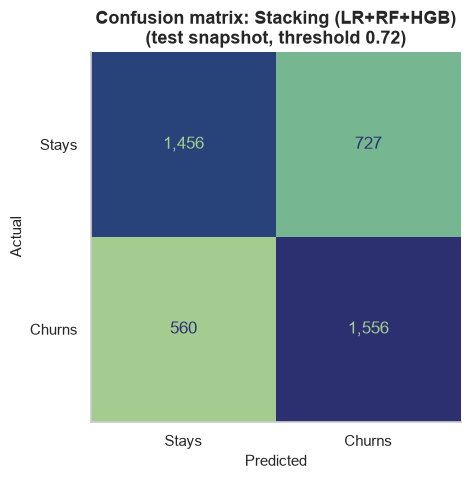

In [35]:
p_best = test_proba[BEST]
compare_thr = pd.DataFrame({
    f"threshold = {t:.2f}": {"Precision": precision_score(y_test, p_best >= t), "Recall": recall_score(y_test, p_best >= t),
                             "F1": f1_score(y_test, p_best >= t),
                             "Share flagged": (p_best >= t).mean(), "Actual churn rate": y_test.mean()}
    for t in [0.5, THRESHOLD]}).T
display(compare_thr)

fig, ax = plt.subplots(figsize=(5.5, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, p_best >= THRESHOLD), display_labels=["Stays", "Churns"]).plot(
    ax=ax, cmap=SEQ_CMAP, colorbar=False, values_format=",")
ax.grid(False)
style(ax, f"Confusion matrix: {BEST}\n(test snapshot, threshold {THRESHOLD:.2f})", "Predicted", "Actual")
plt.show()

### 6.4 Interpretation

**Shallow decision tree.** A depth-3 tree trained on the same data gives a human-readable rulebook. It is not the production model.

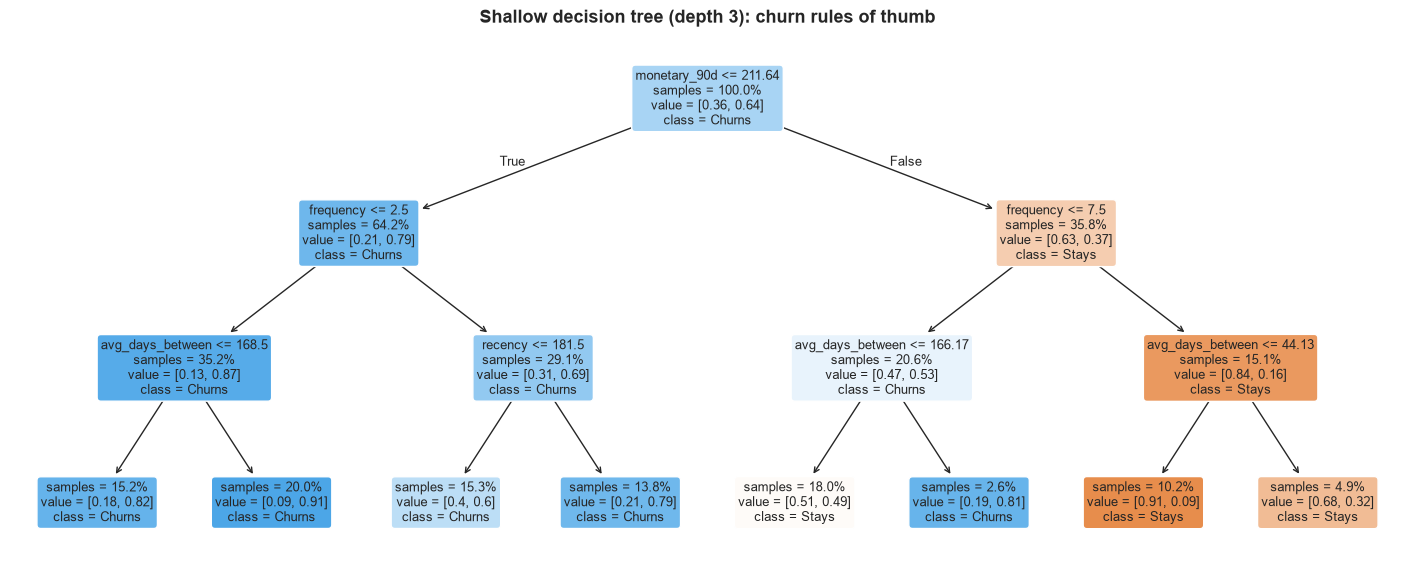

In [36]:
shallow = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=SEED).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(shallow, feature_names=FEATURES, class_names=["Stays", "Churns"], filled=True, rounded=True,
          impurity=False, proportion=True, precision=2, fontsize=9, ax=ax)
style(ax, "Shallow decision tree (depth 3): churn rules of thumb")
plt.show()

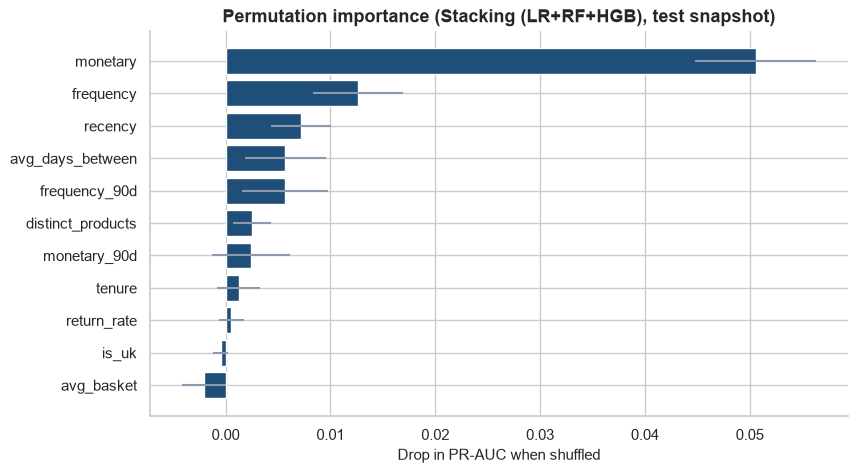

In [37]:
# Permutation importance on the TEST snapshot: how much does PR-AUC drop when a feature is shuffled?
perm = permutation_importance(models[BEST], X_test, y_test, scoring="average_precision",
                              n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=FEATURES).sort_values("mean")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(imp.index, imp["mean"], xerr=imp["std"], color=MAIN, ecolor=PALETTE[6])
style(ax, f"Permutation importance ({BEST}, test snapshot)", "Drop in PR-AUC when shuffled", None)
plt.show()

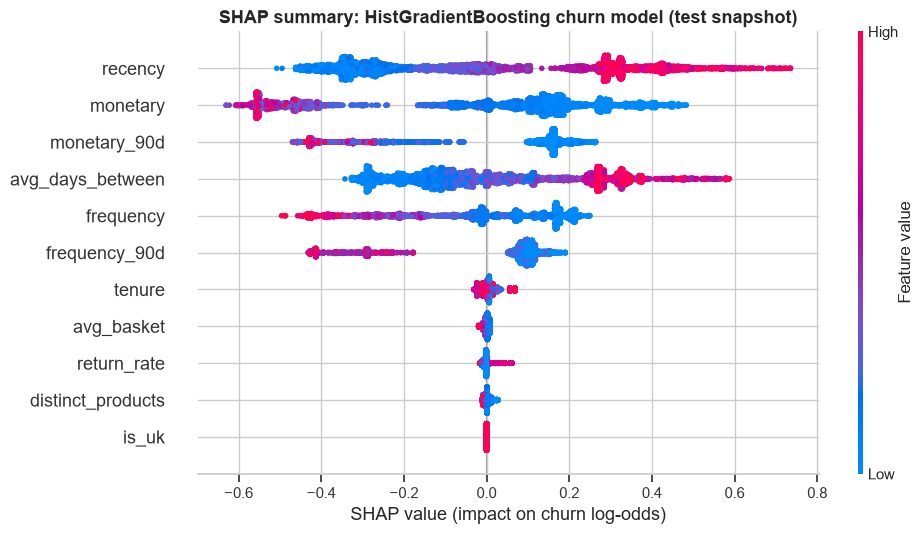

In [38]:
# SHAP values for the tuned gradient-boosting model (tree explainer = exact and fast)
try:
    import shap
    hgb_model = models["HistGradientBoosting"].named_steps["model"]
    explainer = shap.TreeExplainer(hgb_model)
    shap_values = explainer(X_test)
    plt.figure()
    shap.summary_plot(shap_values, X_test, show=False, plot_size=(10, 5.5))
    plt.title("SHAP summary: HistGradientBoosting churn model (test snapshot)", fontweight="bold")
    plt.xlabel("SHAP value (impact on churn log-odds)")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("SHAP is not installed; permutation importance above is used instead.")

**Takeaway:**
- **What drives churn:** the customer's **lifetime value and purchase history** (`monetary`, `frequency`) and their **recent activity** (`recency`, last-90-day spend and orders, usual gap between orders). Big, frequent, recently active buyers almost never churn. Small accounts whose last order is older than their usual buying rhythm usually do. Country, basket size and return rate add little.
- **Models:** all six models land within a few points of each other (test ROC-AUC ≈ 0.76). The tuned ensembles and the stacking model are only marginally better than **logistic regression** and even Naive Bayes. Good feature engineering matters more here than model complexity. If simplicity and explainability matter, logistic regression is a perfectly defensible production choice.
- **Generalisation:** CV scores on the summer snapshot are higher than test scores on the autumn snapshot. This is the honest cost of out-of-time validation under seasonal drift. A random split would have hidden it.
- **Threshold:** Youden's J moves the threshold above 0.5. The flagged share is then close to the true churn rate, and precision improves at the cost of some recall, which is a balanced contact list for a retention campaign.

# 7. Customer value prediction (regression)

**Question:** how much will each active customer spend in the next 90 days?

This uses the same out-of-time design and features as section 6. The target is revenue (£) in the 90 days after the cutoff, and it is £0 for churners. That makes it **zero-inflated and extremely right-skewed**.

- **Baseline: Linear Regression** on log-transformed, scaled features (inside a Pipeline), predicting £ directly.
- **Ensemble: HistGradientBoostingRegressor with a Poisson loss.** The Poisson loss is designed for non-negative, skewed targets with many zeros. It models the *log of the expected spend*, but unlike training on `log1p(spend)` its predictions stay unbiased for the mean, so the totals add up to a realistic forecast. Hyperparameters are tuned with RandomizedSearchCV.

Besides MAE / RMSE / R², we report **Spearman's rank correlation**, because in practice the model is used to *rank* accounts.

As a reference we also include a **naive heuristic**: *"next 90 days = last 90 days"*. A model that cannot beat it is not useful.

In [39]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

reg_models = {"Linear Regression": Pipeline(log_scale + [("model", LinearRegression())])}

hgb_reg_search = RandomizedSearchCV(
    Pipeline([("model", HistGradientBoostingRegressor(loss="poisson", random_state=SEED))]),
    param_distributions={
        "model__learning_rate": [0.02, 0.05, 0.1],
        "model__max_iter": [100, 200, 400],
        "model__max_leaf_nodes": [7, 15, 31],
        "model__min_samples_leaf": [20, 50, 100],
        "model__l2_regularization": [0.0, 0.1, 1.0],
    },
    n_iter=20, scoring="neg_mean_poisson_deviance", cv=kf, random_state=SEED, n_jobs=-1)
hgb_reg_search.fit(X_train, spend_train)
print("HGB regressor best params:", hgb_reg_search.best_params_)
reg_models["HistGradientBoosting (Poisson)"] = hgb_reg_search.best_estimator_

HGB regressor best params: {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 7, 'model__max_iter': 400, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.0}


In [40]:
reg_pred = {"Naive (last 90 days)": X_test.monetary_90d.values}
for name, model in reg_models.items():
    model.fit(X_train, spend_train)
    reg_pred[name] = np.clip(model.predict(X_test), 0, None)

reg_results = pd.DataFrame({
    name: {"MAE (£)": mean_absolute_error(spend_test, p),
           "RMSE (£)": root_mean_squared_error(spend_test, p),
           "R2 (£)": r2_score(spend_test, p),
           "Spearman rho": spearmanr(spend_test, p).statistic,
           "Predicted total (£)": p.sum()}
    for name, p in reg_pred.items()}).T
reg_results.loc["Actual", "Predicted total (£)"] = spend_test.sum()
reg_results

,MAE (£),RMSE (£),R2 (£),Spearman rho,Predicted total (£)
Naive (last 90 days),492.571,"2,391.638",0.535,0.448,"1,796,875.620"
Linear Regression,610.264,"3,187.125",0.174,0.412,"2,428,066.298"
HistGradientBoosting (Poisson),453.251,"2,305.006",0.568,0.540,"1,834,834.835"
Actual,NaN,NaN,NaN,NaN,"2,732,282.990"


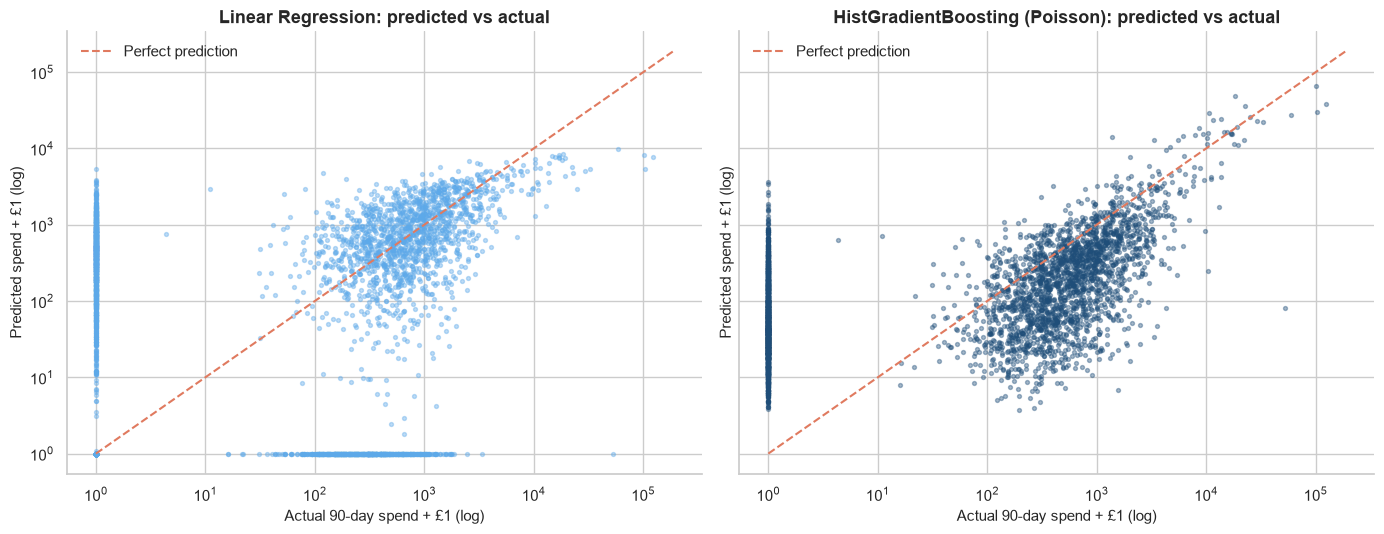

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
lims = (1, spend_test.max() * 1.5)
for ax, name, color in zip(axes, ["Linear Regression", "HistGradientBoosting (Poisson)"], [PALETTE[5], MAIN]):
    ax.scatter(spend_test + 1, reg_pred[name] + 1, s=8, alpha=0.4, color=color)
    ax.plot(lims, lims, ls="--", color=ACCENT, label="Perfect prediction")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.legend(loc="upper left")
    style(ax, f"{name}: predicted vs actual", "Actual 90-day spend + £1 (log)", "Predicted spend + £1 (log)")
plt.tight_layout()
plt.show()

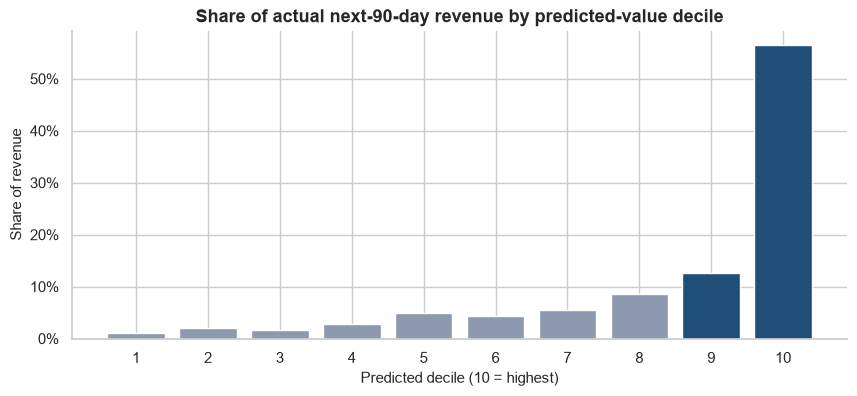

Top 2 predicted deciles (20% of customers) capture 69% of actual future revenue


In [42]:
# Business check: do customers ranked highest by the model actually spend the most? (decile lift)
dec = pd.DataFrame({"pred": reg_pred["HistGradientBoosting (Poisson)"], "actual": spend_test.values})
dec["decile"] = pd.qcut(dec.pred.rank(method="first"), 10, labels=range(1, 11))
dec_share = dec.groupby("decile", observed=True).actual.sum() / dec.actual.sum()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(dec_share.index.astype(str), dec_share.values, color=[MAIN if d >= 9 else PALETTE[6] for d in dec_share.index])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
style(ax, "Share of actual next-90-day revenue by predicted-value decile", "Predicted decile (10 = highest)", "Share of revenue")
plt.show()
print(f"Top 2 predicted deciles (20% of customers) capture {dec_share.loc[[9, 10]].sum():.0%} of actual future revenue")

**Takeaway:**
- The **Poisson gradient-boosting model beats both the linear baseline and the naive heuristic on every metric** (MAE, RMSE, R², Spearman). The linear model is actually *worse* than the naive rule. It cannot represent the "zero for churners, large for loyal buyers" shape and often predicts negative spend, which gets clipped to £0 (the horizontal band at the bottom of its plot).
- Predicting *exact* £ amounts per customer is still hard (R² around 0.5). Wholesale orders are lumpy, and a few very large buyers dominate the errors.
- **Ranking is what matters for the business:** the 20% of customers with the highest predicted value account for roughly **70% of next quarter's actual revenue**.
- **All models underestimate the total.** They learned from a summer window, and the test window is the Christmas peak. A production version should train on the same quarter of the previous year or add seasonal features.

# 8. Conclusions

**Question:** what did we learn, and what should the business do with it?

The key numbers below are pulled straight from the results computed above.

In [43]:
key = pd.Series({
    "Clean rows kept (% of raw)": f"{len(df) / len(raw):.1%}",
    "UK share of revenue": f"{uk_share:.1%}",
    "Association rules found (lift >= 1.5)": f"{len(rules):,}",
    "Max rule lift": f"{rules.lift.max():.1f}",
    "Customer segments (k)": K_BEST,
    "K-Means vs Ward agreement (ARI)": f"{ari:.2f}",
    "Champions: share of customers / revenue": "{:.0%} / {:.0%}".format(
        *seg_profile.loc["Champions", ["share_customers", "share_revenue"]]) if "Champions" in seg_profile.index else "n/a",
    "Best churn model (by CV PR-AUC)": BEST,
    "Best churn model test ROC-AUC / PR-AUC": f"{results.loc[BEST, 'ROC-AUC']:.3f} / {results.loc[BEST, 'PR-AUC']:.3f}",
    f"Churn recall at chosen threshold {THRESHOLD:.2f}": f"{recall_score(y_test, p_best >= THRESHOLD):.1%}",
    "Spend model R2 (£): Linear vs HGB-Poisson": f"{reg_results.loc['Linear Regression', 'R2 (£)']:.3f} vs "
                                                f"{reg_results.loc['HistGradientBoosting (Poisson)', 'R2 (£)']:.3f}",
    "Revenue captured by top 20% predicted customers": f"{dec_share.loc[[9, 10]].sum():.0%}",
}, name="value")
key.to_frame()

,value
Clean rows kept (% of raw),72.2%
UK share of revenue,83.5%
Association rules found (lift >= 1.5),"1,006"
Max rule lift,30.9
Customer segments (k),4
K-Means vs Ward agreement (ARI),0.44
Champions: share of customers / revenue,34% / 84%
Best churn model (by CV PR-AUC),Stacking (LR+RF+HGB)
Best churn model test ROC-AUC / PR-AUC,0.765 / 0.719
Churn recall at chosen threshold 0.72,73.5%


### Findings per section
- **Data quality:** about 22% of the raw lines have no customer ID, and duplicates (partly from the overlapping sheets), cancellations, fees and reversed orders add more noise. About 72% of lines survive a documented, step-by-step cleaning log.
- **EDA:** revenue is very seasonal (November peak) and flat year over year. About 84% of it comes from the UK, and orders arrive during weekday office hours, which fits a B2B wholesale shop.
- **Association rules:** the strongest rules (lift up to ~30) link variants of the same product family, such as Regency teacups in different colours, matching metal signs and cutlery sets. That gives "complete the set" cross-sell opportunities that are easy to explain to non-technical colleagues.
- **Segmentation:** four segments (Champions, At Risk, New Customers, Lost) along a value axis and a lifecycle axis (PCA). About a third of customers (Champions) generate over 80% of revenue. K-Means beats Ward on internal metrics, and the two agree only moderately, so segment boundaries are a convention on a continuum.
- **Churn:** under a strict out-of-time setup all models reach a test ROC-AUC of about 0.76. Ensembles are only marginally better than logistic regression. Lifetime value and recent activity dominate the explanations (permutation importance, SHAP, shallow tree).
- **Customer value:** a Poisson gradient-boosting model beats both the linear baseline and the naive "same as last quarter" rule. Its top 20% of predicted customers capture about 70% of next quarter's revenue.

### Business recommendations
1. **Protect the Champions.** Give them priority service, early access to the Christmas range (orders ramp up from September) and loyalty pricing.
2. **Win back At Risk customers** with the churn model's flagged list. Contact them on weekday mornings and use the association rules to personalise the offer ("complete your teacup collection").
3. **Don't overspend on Lost customers.** Low-cost automated e-mails only.
4. **Use the value model for targeting**: rank accounts by predicted spend × churn probability to decide where sales effort goes.

### Limitations
- Customers without an ID (~22% of lines) are excluded, so results describe registered customers only.
- The test label window (Sep-Dec) contains the Christmas peak while the training window (Jun-Sep) does not. That seasonal shift lowers the churn rate and raises spend in the test period, so probabilities are not calibrated for Q4 and spend totals are underestimated. Only one training snapshot is used.
- Return rate is approximated by counting cancellation invoices. Only exact customer/product/quantity matches are used to remove reversed purchases, so partial returns stay in revenue.
- There is no cost or margin data. Youden's J stands in for a real cost-benefit analysis when choosing the threshold.

### Next steps
- Train on **several stacked cutoffs** (e.g. monthly snapshots) to get more training examples and cover all seasons.
- Add **seasonality and product-mix features** (share of Christmas items, category preferences) and test calibrated probabilities.
- Replace Youden's J with an explicit **profit-based threshold** once campaign costs and margins are known.
- Try probabilistic CLV models (BG/NBD + Gamma-Gamma) as a benchmark for the value model.